In [ ]:
print("Python is working!")

Python is working!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("All libraries are working!")

All libraries are working!


In [ ]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.26.0-py3-none-any.whl (474 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ -


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

# Load the Rossmann datasets
train = pd.read_csv("rossmann-store-sales/train.csv")
test = pd.read_csv("rossmann-store-sales/test.csv")
store = pd.read_csv("rossmann-store-sales/store.csv")

# Check the size of each dataset
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Store shape:", store.shape)

Train shape: (1017209, 9)
Test shape: (41088, 8)
Store shape: (1115, 10)


C:\Users\Riya\AppData\Local\Temp\ipykernel_27380\1679018819.py:4: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("rossmann-store-sales/train.csv")


In [3]:
# Look at the first 5 rows of each dataset

print("TRAIN DATA")
display(train.head())

print("\nTEST DATA")
display(test.head())

print("\nSTORE DATA")
display(store.head())

TRAIN DATA


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1



TEST DATA


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0



STORE DATA


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [4]:
# Check the columns and data types

print("TRAIN INFO")
train.info()

print("\nSTORE INFO")
store.info()

TRAIN INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB

STORE INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-nul

In [5]:
# Check for missing values and duplicate rows

print("Missing values in TRAIN:")
print(train.isnull().sum())

print("\nDuplicate rows in TRAIN:")
print(train.duplicated().sum())

print("\nUnique values in important columns:")
print("Stores:", train["Store"].nunique())
print("Open:", train["Open"].unique())
print("Promo:", train["Promo"].unique())
print("StateHoliday:", train["StateHoliday"].unique())
print("SchoolHoliday:", train["SchoolHoliday"].unique())

Missing values in TRAIN:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Duplicate rows in TRAIN:
0

Unique values in important columns:
Stores: 1115
Open: [1 0]
Promo: [1 0]
StateHoliday: ['0' 'a' 'b' 'c' 0]
SchoolHoliday: [1 0]


In [6]:
# Convert Date from text to datetime

train["Date"] = pd.to_datetime(train["Date"])
test["Date"] = pd.to_datetime(test["Date"])

print("Train date range:", train["Date"].min(), "to", train["Date"].max())
print("Test date range:", test["Date"].min(), "to", test["Date"].max())

Train date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00
Test date range: 2015-08-01 00:00:00 to 2015-09-17 00:00:00


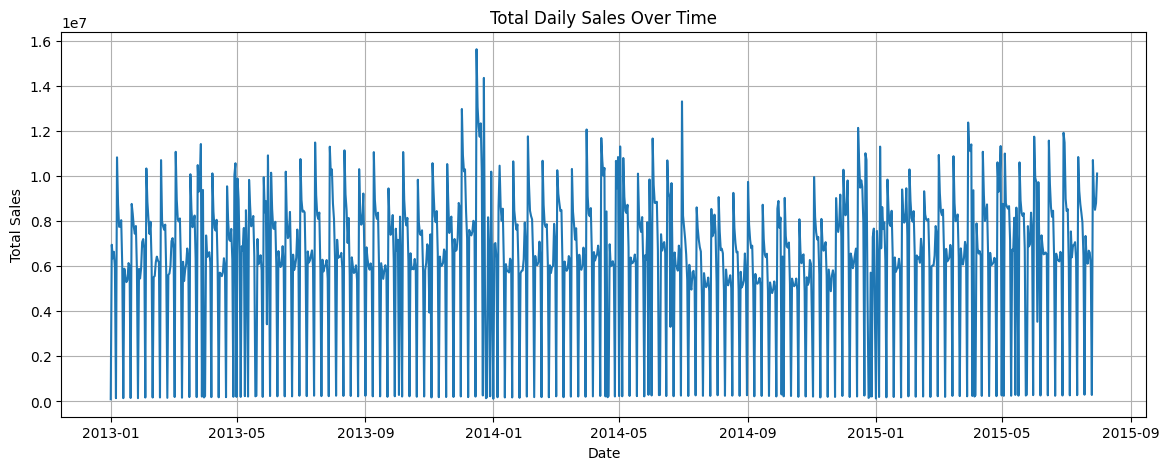

In [9]:
# Total daily sales over time

daily_sales = train.groupby("Date")["Sales"].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales)
plt.title("Total Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

In [8]:
import matplotlib.pyplot as plt

Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64


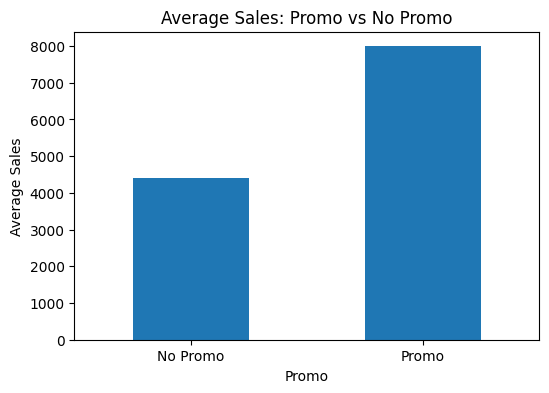

In [10]:
# Compare average sales with and without promotions

promo_sales = train.groupby("Promo")["Sales"].mean()

print(promo_sales)

plt.figure(figsize=(6, 4))
promo_sales.plot(kind="bar")
plt.title("Average Sales: Promo vs No Promo")
plt.xlabel("Promo")
plt.ylabel("Average Sales")
plt.xticks([0, 1], ["No Promo", "Promo"], rotation=0)
plt.show()

DayOfWeek
1    7809.044510
2    7005.244467
3    6555.884138
4    6247.575913
5    6723.274305
6    5847.562599
7     204.183189
Name: Sales, dtype: float64


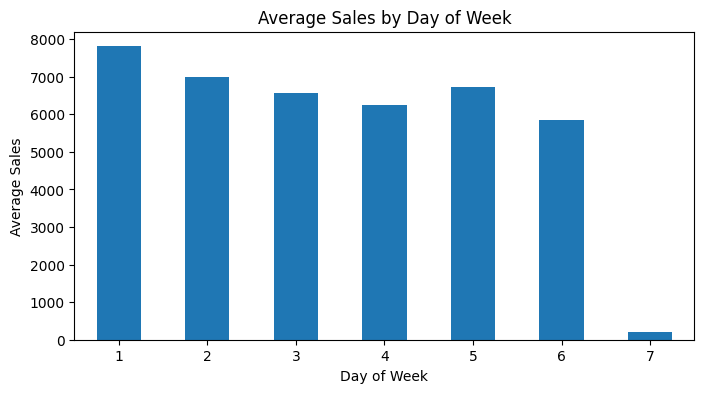

In [11]:
# Average sales by day of the week

day_sales = train.groupby("DayOfWeek")["Sales"].mean()

print(day_sales)

plt.figure(figsize=(8, 4))
day_sales.plot(kind="bar")
plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.show()

DayOfWeek
1    8216.073074
2    7088.113656
3    6728.122978
4    6767.310159
5    7072.677012
6    5874.840238
7    8224.723908
Name: Sales, dtype: float64


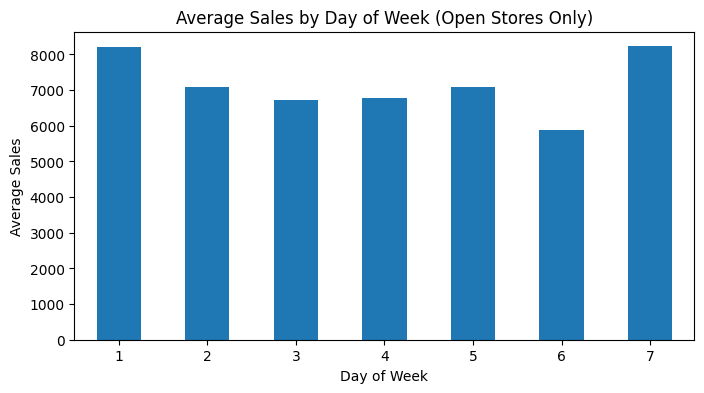

In [12]:
# Average sales by day of week for OPEN stores only

open_train = train[train["Open"] == 1]

day_sales_open = open_train.groupby("DayOfWeek")["Sales"].mean()

print(day_sales_open)

plt.figure(figsize=(8, 4))
day_sales_open.plot(kind="bar")
plt.title("Average Sales by Day of Week (Open Stores Only)")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.show()

Month
1     6563.690444
2     6589.165535
3     6976.412026
4     7046.228420
5     7106.453154
6     7000.978190
7     6952.682125
8     6648.984654
9     6546.343035
10    6602.843354
11    7188.554250
12    8608.956661
Name: Sales, dtype: float64


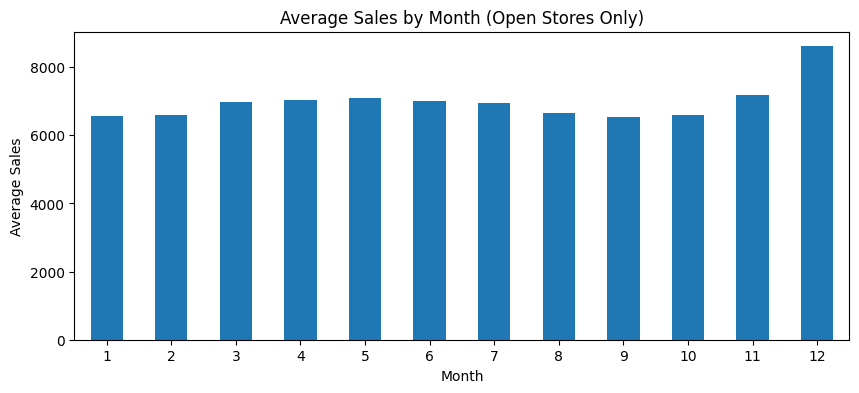

In [15]:
# Extract month from Date

# Create Month and update open_train

train["Month"] = train["Date"].dt.month
open_train = train[train["Open"] == 1]

monthly_sales = open_train.groupby("Month")["Sales"].mean()

print(monthly_sales)

plt.figure(figsize=(10, 4))
monthly_sales.plot(kind="bar")
plt.title("Average Sales by Month (Open Stores Only)")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.show()

In [14]:
# Check Sunday: open vs closed stores

sunday = train[train["DayOfWeek"] == 7]

print("Sunday observations:")
print(sunday["Open"].value_counts())

print("\nSunday average sales:")
print(sunday.groupby("Open")["Sales"].mean())

Sunday observations:
Open
0    141137
1      3593
Name: count, dtype: int64

Sunday average sales:
Open
0       0.000000
1    8224.723908
Name: Sales, dtype: float64


In [16]:
# Check store types

print("Store types:")
print(store["StoreType"].value_counts())

print("\nAverage sales by store type:")
store_type_sales = train.merge(store[["Store", "StoreType"]], on="Store")

print(store_type_sales.groupby("StoreType")["Sales"].mean())

Store types:
StoreType
a    602
d    348
c    148
b     17
Name: count, dtype: int64

Average sales by store type:
StoreType
a     5738.179710
b    10058.837334
c     5723.629246
d     5641.819243
Name: Sales, dtype: float64


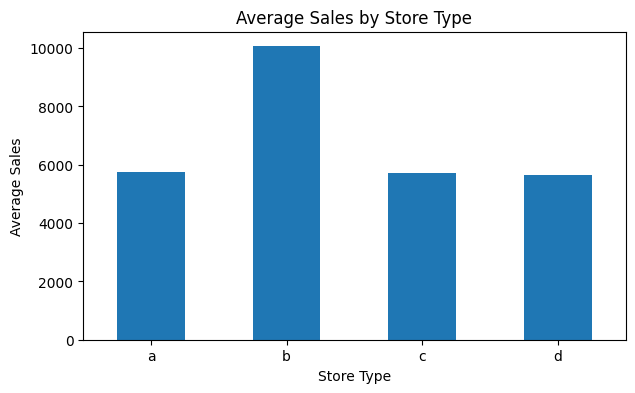

In [17]:
# Average sales by store type

store_type_sales = store_type_sales.groupby("StoreType")["Sales"].mean()

plt.figure(figsize=(7, 4))
store_type_sales.plot(kind="bar")
plt.title("Average Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.show()

Average Sales by Promotion:
Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64


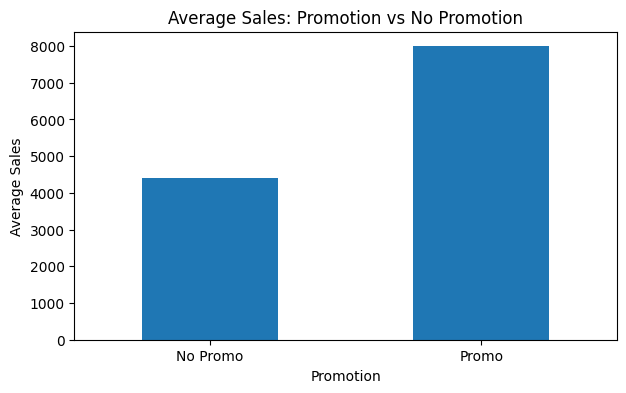

In [18]:
# Average sales by promotion status

promo_sales = train.groupby("Promo")["Sales"].mean()

print("Average Sales by Promotion:")
print(promo_sales)

plt.figure(figsize=(7, 4))
promo_sales.plot(kind="bar")
plt.title("Average Sales: Promotion vs No Promotion")
plt.xlabel("Promotion")
plt.ylabel("Average Sales")
plt.xticks([0, 1], ["No Promo", "Promo"], rotation=0)
plt.show()

In [19]:
# Check competition information

print("Store columns:")
print(store.columns.tolist())

print("\nCompetition distance summary:")
print(store["CompetitionDistance"].describe())

Store columns:
['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']

Competition distance summary:
count     1112.000000
mean      5404.901079
std       7663.174720
min         20.000000
25%        717.500000
50%       2325.000000
75%       6882.500000
max      75860.000000
Name: CompetitionDistance, dtype: float64


In [20]:
# Merge competition distance with sales data

competition_data = train.merge(
    store[["Store", "CompetitionDistance"]],
    on="Store",
    how="left"
)

# Create distance groups
competition_data["CompetitionGroup"] = pd.cut(
    competition_data["CompetitionDistance"],
    bins=[0, 1000, 2500, 5000, 10000, float("inf")],
    labels=[
        "0-1 km",
        "1-2.5 km",
        "2.5-5 km",
        "5-10 km",
        "10+ km"
    ]
)

# Average sales by competition distance
competition_sales = (
    competition_data
    .groupby("CompetitionGroup", observed=True)["Sales"]
    .mean()
)

print("Average Sales by Competition Distance:")
print(competition_sales)


Average Sales by Competition Distance:
CompetitionGroup
0-1 km      6063.365791
1-2.5 km    5715.756212
2.5-5 km    5623.084127
5-10 km     5567.718124
10+ km      5685.546657
Name: Sales, dtype: float64


Average Sales by Assortment Type:
Assortment
a    5481.026096
b    8553.931999
c    6058.676567
Name: Sales, dtype: float64


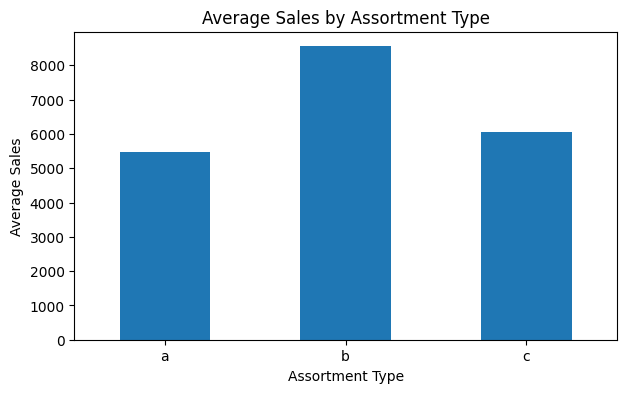

In [21]:
# Average sales by assortment type

assortment_sales = (
    train.merge(
        store[["Store", "Assortment"]],
        on="Store",
        how="left"
    )
    .groupby("Assortment")["Sales"]
    .mean()
)

print("Average Sales by Assortment Type:")
print(assortment_sales)

plt.figure(figsize=(7, 4))
assortment_sales.plot(kind="bar")
plt.title("Average Sales by Assortment Type")
plt.xlabel("Assortment Type")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.show()

In [22]:
# Merge sales data with store information

df = train.merge(
    store,
    on="Store",
    how="left"
)

print("New dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

New dataset shape: (1017209, 19)

Columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Month', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Month,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,7,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,7,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,7,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,7,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,7,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [23]:
# Make sure Date is in datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Create useful date features
df["Year"] = df["Date"].dt.year
df["Day"] = df["Date"].dt.day
df["WeekOfYear"] = df["Date"].dt.isocalendar().week.astype(int)

print("New features created:")
print(df[["Date", "Year", "Month", "Day", "DayOfWeek", "WeekOfYear"]].head())

New features created:
        Date  Year  Month  Day  DayOfWeek  WeekOfYear
0 2015-07-31  2015      7   31          5          31
1 2015-07-31  2015      7   31          5          31
2 2015-07-31  2015      7   31          5          31
3 2015-07-31  2015      7   31          5          31
4 2015-07-31  2015      7   31          5          31


In [24]:
# Check missing values in our merged dataset

missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])

Missing values:
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64


In [25]:
# Handle missing values

# Competition distance: use median
df["CompetitionDistance"] = df["CompetitionDistance"].fillna(
    df["CompetitionDistance"].median()
)

# Competition opening information: 0 means information unavailable
df["CompetitionOpenSinceMonth"] = df["CompetitionOpenSinceMonth"].fillna(0)
df["CompetitionOpenSinceYear"] = df["CompetitionOpenSinceYear"].fillna(0)

# Promo2 information: 0 / None means the store does not have Promo2
df["Promo2SinceWeek"] = df["Promo2SinceWeek"].fillna(0)
df["Promo2SinceYear"] = df["Promo2SinceYear"].fillna(0)
df["PromoInterval"] = df["PromoInterval"].fillna("None")

# Check again
print("Remaining missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Remaining missing values:
Series([], dtype: int64)


In [26]:
# Calculate how long competition has been open

df["CompetitionOpenMonths"] = (
    (df["Year"] - df["CompetitionOpenSinceYear"]) * 12
    + (df["Month"] - df["CompetitionOpenSinceMonth"])
)

# For stores without competition information, set to 0
df.loc[
    (df["CompetitionOpenSinceYear"] == 0) |
    (df["CompetitionOpenSinceMonth"] == 0),
    "CompetitionOpenMonths"
] = 0

print(df[[
    "Store",
    "Year",
    "Month",
    "CompetitionOpenSinceYear",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenMonths"
]].head(10))

   Store  Year  Month  CompetitionOpenSinceYear  CompetitionOpenSinceMonth  \
0      1  2015      7                    2008.0                        9.0   
1      2  2015      7                    2007.0                       11.0   
2      3  2015      7                    2006.0                       12.0   
3      4  2015      7                    2009.0                        9.0   
4      5  2015      7                    2015.0                        4.0   
5      6  2015      7                    2013.0                       12.0   
6      7  2015      7                    2013.0                        4.0   
7      8  2015      7                    2014.0                       10.0   
8      9  2015      7                    2000.0                        8.0   
9     10  2015      7                    2009.0                        9.0   

   CompetitionOpenMonths  
0                   82.0  
1                   92.0  
2                  103.0  
3                   70.0  
4     

In [27]:
# Calculate how long Promo2 has been running

df["Promo2OpenMonths"] = (
    (df["Year"] - df["Promo2SinceYear"]) * 12
    + (df["WeekOfYear"] - df["Promo2SinceWeek"]) / 4
)

# Stores without Promo2 get 0
df.loc[df["Promo2"] == 0, "Promo2OpenMonths"] = 0

# Check the result
print(df[[
    "Store",
    "Year",
    "WeekOfYear",
    "Promo2",
    "Promo2SinceYear",
    "Promo2SinceWeek",
    "Promo2OpenMonths"
]].head(10))

   Store  Year  WeekOfYear  Promo2  Promo2SinceYear  Promo2SinceWeek  \
0      1  2015          31       0              0.0              0.0   
1      2  2015          31       1           2010.0             13.0   
2      3  2015          31       1           2011.0             14.0   
3      4  2015          31       0              0.0              0.0   
4      5  2015          31       0              0.0              0.0   
5      6  2015          31       0              0.0              0.0   
6      7  2015          31       0              0.0              0.0   
7      8  2015          31       0              0.0              0.0   
8      9  2015          31       0              0.0              0.0   
9     10  2015          31       0              0.0              0.0   

   Promo2OpenMonths  
0              0.00  
1             64.50  
2             52.25  
3              0.00  
4              0.00  
5              0.00  
6              0.00  
7              0.00  
8        

In [28]:
# Columns we will use for the ML model

features = [
    "Store",
    "DayOfWeek",
    "Open",
    "Promo",
    "StateHoliday",
    "SchoolHoliday",
    "Month",
    "Year",
    "Day",
    "WeekOfYear",
    "StoreType",
    "Assortment",
    "CompetitionDistance",
    "CompetitionOpenMonths",
    "Promo2",
    "Promo2OpenMonths",
    "PromoInterval"
]

target = "Sales"

print("Number of features:", len(features))
print("\nFeatures:")
print(features)

print("\nTarget:", target)

Number of features: 17

Features:
['Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Month', 'Year', 'Day', 'WeekOfYear', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenMonths', 'Promo2', 'Promo2OpenMonths', 'PromoInterval']

Target: Sales


In [29]:
# Keep only open stores for sales forecasting
df_model = df[df["Open"] == 1].copy()

print("Original dataset:", df.shape)
print("Open stores only:", df_model.shape)

Original dataset: (1017209, 24)
Open stores only: (844392, 24)


In [30]:
# Separate features and target

X = df_model.drop(columns=["Sales", "Date"])
y = df_model["Sales"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

X shape: (844392, 22)
y shape: (844392,)

Features:
['Store', 'DayOfWeek', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Month', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'Year', 'Day', 'WeekOfYear', 'CompetitionOpenMonths', 'Promo2OpenMonths']


In [31]:
# Remove Customers because it is not available when forecasting future sales

X = X.drop(columns=["Customers"])

print("X shape:", X.shape)
print("Number of features:", X.shape[1])
print("Features:")
print(X.columns.tolist())

X shape: (844392, 21)
Number of features: 21
Features:
['Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Month', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'Year', 'Day', 'WeekOfYear', 'CompetitionOpenMonths', 'Promo2OpenMonths']


In [32]:
# Check data types of our features

print(X.dtypes)

Store                          int64
DayOfWeek                      int64
Open                           int64
Promo                          int64
StateHoliday                  object
SchoolHoliday                  int64
Month                          int32
StoreType                     object
Assortment                    object
CompetitionDistance          float64
CompetitionOpenSinceMonth    float64
CompetitionOpenSinceYear     float64
Promo2                         int64
Promo2SinceWeek              float64
Promo2SinceYear              float64
PromoInterval                 object
Year                           int32
Day                            int32
WeekOfYear                     int64
CompetitionOpenMonths        float64
Promo2OpenMonths             float64
dtype: object


In [33]:
# Convert categorical variables into numerical variables

X_encoded = pd.get_dummies(
    X,
    columns=["StateHoliday", "StoreType", "Assortment", "PromoInterval"],
    drop_first=True
)

print("Original number of features:", X.shape[1])
print("Number of features after encoding:", X_encoded.shape[1])

print("\nEncoded features:")
print(X_encoded.columns.tolist())

Original number of features: 21
Number of features after encoding: 29

Encoded features:
['Store', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'Month', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'Year', 'Day', 'WeekOfYear', 'CompetitionOpenMonths', 'Promo2OpenMonths', 'StateHoliday_0', 'StateHoliday_a', 'StateHoliday_b', 'StateHoliday_c', 'StoreType_b', 'StoreType_c', 'StoreType_d', 'Assortment_b', 'Assortment_c', 'PromoInterval_Jan,Apr,Jul,Oct', 'PromoInterval_Mar,Jun,Sept,Dec', 'PromoInterval_None']


In [34]:
# Time-based train-validation split

# Training: up to May 2015
train_mask = df_model["Date"] < "2015-06-01"

# Validation: June and July 2015
validation_mask = df_model["Date"] >= "2015-06-01"

X_train = X_encoded.loc[train_mask]
X_val = X_encoded.loc[validation_mask]

y_train = y.loc[train_mask]
y_val = y.loc[validation_mask]

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation data:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTraining period:")
print(df_model.loc[train_mask, "Date"].min(), "to",
      df_model.loc[train_mask, "Date"].max())

print("\nValidation period:")
print(df_model.loc[validation_mask, "Date"].min(), "to",
      df_model.loc[validation_mask, "Date"].max())

Training data:
X_train: (785781, 29)
y_train: (785781,)

Validation data:
X_val: (58611, 29)
y_val: (58611,)

Training period:
2013-01-01 00:00:00 to 2015-05-31 00:00:00

Validation period:
2015-06-01 00:00:00 to 2015-07-31 00:00:00


In [35]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [36]:
# Make predictions on the validation data

y_pred = rf_model.predict(X_val)

# Calculate evaluation metrics
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print("Model Performance")
print("-----------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))

Model Performance
-----------------
MAE : 906.78
RMSE: 1337.28


In [37]:
# Calculate RMSPE (Root Mean Square Percentage Error)

rmspe = np.sqrt(
    np.mean(
        ((y_val - y_pred) / y_val) ** 2
    )
)

print("RMSPE:", round(rmspe, 4))
print("RMSPE (%):", round(rmspe * 100, 2), "%")

RMSPE: 0.1956
RMSPE (%): 19.56 %


In [38]:
# Compare actual vs predicted sales

comparison = pd.DataFrame({
    "Actual Sales": y_val.values,
    "Predicted Sales": y_pred
})

print(comparison.head(10))

   Actual Sales  Predicted Sales
0          5263      6098.963115
1          6064      7253.421430
2          8314      9373.073311
3         13995     12791.073101
4          4822      6704.749762
5          5651      6727.752370
6         15344     12346.354879
7          8492      7079.341035
8          8565      9086.024431
9          7185      6792.044285


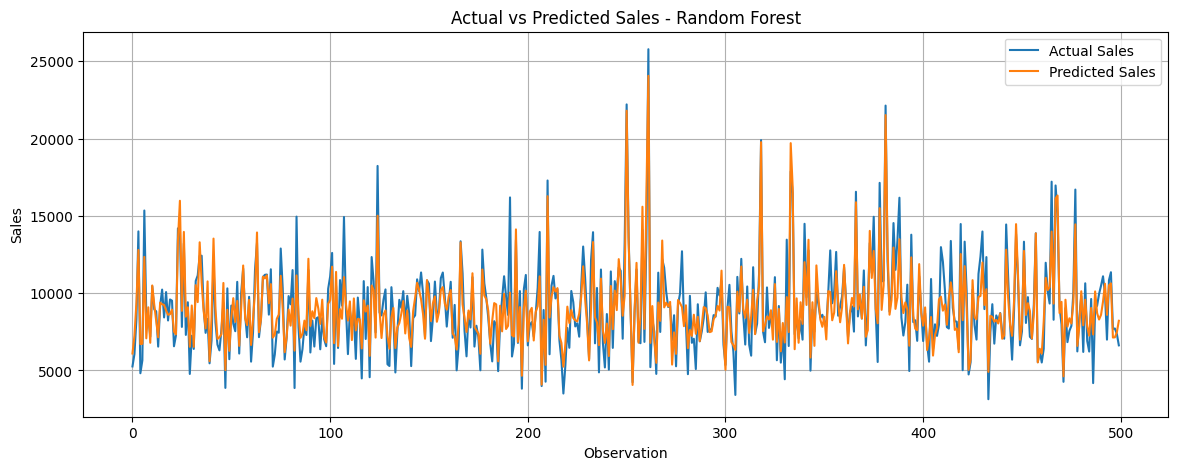

In [39]:
# Plot actual vs predicted sales

plt.figure(figsize=(14, 5))

plt.plot(y_val.values[:500], label="Actual Sales")
plt.plot(y_pred[:500], label="Predicted Sales")

plt.title("Actual vs Predicted Sales - Random Forest")
plt.xlabel("Observation")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

In [40]:
# Feature importance from Random Forest

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                           Feature  Importance
6              CompetitionDistance    0.190438
3                            Promo    0.149906
0                            Store    0.143556
8         CompetitionOpenSinceYear    0.069833
1                        DayOfWeek    0.065839
7        CompetitionOpenSinceMonth    0.060487
15           CompetitionOpenMonths    0.043041
11                 Promo2SinceYear    0.039752
14                      WeekOfYear    0.031435
21                     StoreType_b    0.030516
13                             Day    0.030364
10                 Promo2SinceWeek    0.029719
25                    Assortment_c    0.027300
16                Promo2OpenMonths    0.017899
22                     StoreType_c    0.016618
23                     StoreType_d    0.012393
5                            Month    0.011796
27  PromoInterval_Mar,Jun,Sept,Dec    0.007027
26   PromoInterval_Jan,Apr,Jul,Oct    0.006146
4                    SchoolHoliday    0.005656
12           

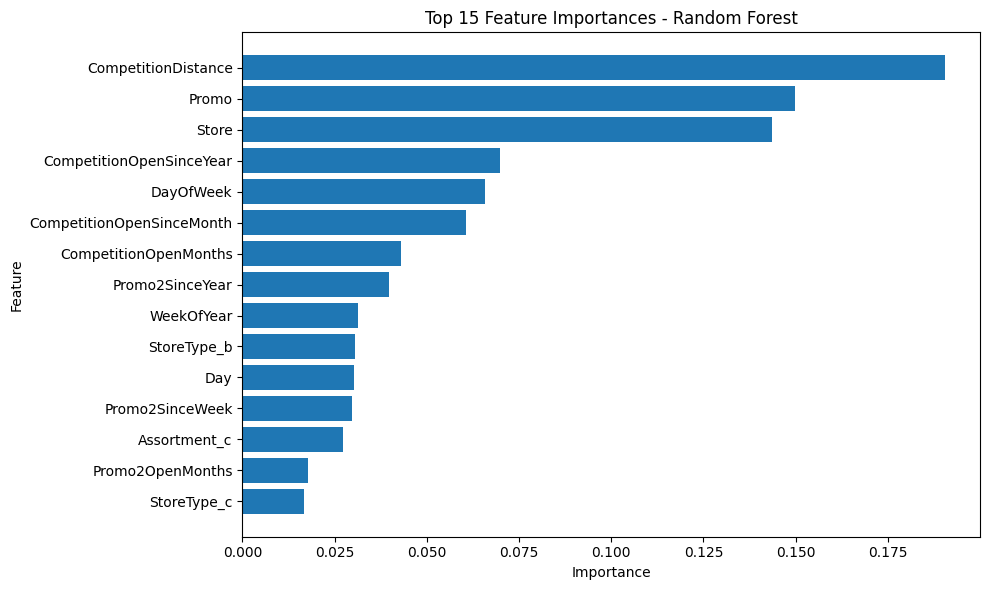

In [41]:
# Plot top 15 feature importances

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [42]:
from sklearn.ensemble import GradientBoostingRegressor

# Create Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [43]:
# Make predictions on validation data
gb_pred = gb_model.predict(X_val)

print("Predictions generated!")
print(gb_pred[:10])

Predictions generated!
[ 7601.88863849  7364.26537366  8462.842581   10264.33920214
  6725.03136313  8068.39066702 10281.68206137  8110.23364728
  9285.4163576   7962.75998782]


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

gb_mae = mean_absolute_error(y_val, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_val, gb_pred))

print("Gradient Boosting Performance")
print("-----------------------------")
print("MAE :", round(gb_mae, 2))
print("RMSE:", round(gb_rmse, 2))

Gradient Boosting Performance
-----------------------------
MAE : 1520.98
RMSE: 2072.88


In [45]:
# Calculate RMSPE
gb_rmspe = np.sqrt(
    np.mean(
        ((y_val - gb_pred) / y_val) ** 2
    )
)

print("RMSPE:", round(gb_rmspe, 4))
print("RMSPE (%):", round(gb_rmspe * 100, 2), "%")

RMSPE: 0.3659
RMSPE (%): 36.59 %


In [46]:
comparison_models = pd.DataFrame({
    "Model": ["Random Forest", "Gradient Boosting"],
    "MAE": [mae, gb_mae],
    "RMSE": [rmse, gb_rmse],
    "RMSPE (%)": [rmspe * 100, gb_rmspe * 100]
})

comparison_models

,Model,MAE,RMSE,RMSPE (%)
0,Random Forest,906.783213,1337.280315,19.560030
1,Gradient Boosting,1520.979760,2072.884429,36.587442


In [47]:
from sklearn.ensemble import RandomForestRegressor

# Improved Random Forest model
rf_tuned = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

print("Training tuned Random Forest...")

rf_tuned.fit(X_train, y_train)

print("Tuned Random Forest trained successfully!")

Training tuned Random Forest...
Tuned Random Forest trained successfully!


In [48]:
# Predictions from tuned Random Forest
rf_tuned_pred = rf_tuned.predict(X_val)

print("Tuned Random Forest predictions generated!")
print(rf_tuned_pred[:10])

Tuned Random Forest predictions generated!
[ 6819.60324837  7408.12874432  9213.58476857 10914.84169616
  6926.52338072  7747.33594328 10176.3679247   7864.30529332
  8396.99381794  7436.54986366]


In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate errors
tuned_mae = mean_absolute_error(y_val, rf_tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_val, rf_tuned_pred))

# Calculate RMSPE
tuned_rmspe = np.sqrt(
    np.mean(
        ((y_val - rf_tuned_pred) / y_val) ** 2
    )
)

print("Tuned Random Forest Performance")
print("--------------------------------")
print("MAE :", round(tuned_mae, 2))
print("RMSE:", round(tuned_rmse, 2))
print("RMSPE:", round(tuned_rmspe, 4))
print("RMSPE (%):", round(tuned_rmspe * 100, 2), "%")

Tuned Random Forest Performance
--------------------------------
MAE : 1011.55
RMSE: 1397.74
RMSPE: 0.2297
RMSPE (%): 22.97 %


In [50]:
# ==========================================
# PREPARE TEST DATA FOR FINAL FORECASTING
# ==========================================

# Merge test data with store information
test_df = test.merge(store, on="Store", how="left")

# Convert Date to datetime
test_df["Date"] = pd.to_datetime(test_df["Date"])

# Create time-based features
test_df["Year"] = test_df["Date"].dt.year
test_df["Month"] = test_df["Date"].dt.month
test_df["Day"] = test_df["Date"].dt.day
test_df["WeekOfYear"] = test_df["Date"].dt.isocalendar().week.astype(int)

print("Test data prepared:")
print("Shape:", test_df.shape)
print("Date range:", test_df["Date"].min(), "to", test_df["Date"].max())

Test data prepared:
Shape: (41088, 21)
Date range: 2015-08-01 00:00:00 to 2015-09-17 00:00:00


In [51]:
# ==========================================
# CREATE COMPETITION & PROMO2 FEATURES
# ==========================================

# CompetitionOpenMonths
test_df["CompetitionOpenMonths"] = (
    (test_df["Year"] - test_df["CompetitionOpenSinceYear"]) * 12
    + (test_df["Month"] - test_df["CompetitionOpenSinceMonth"])
)

# Replace invalid / missing competition values
test_df["CompetitionOpenMonths"] = test_df["CompetitionOpenMonths"].fillna(0)
test_df["CompetitionOpenMonths"] = test_df["CompetitionOpenMonths"].clip(lower=0)


# Promo2OpenMonths
test_df["Promo2OpenMonths"] = (
    (test_df["Year"] - test_df["Promo2SinceYear"]) * 12
    + (
        test_df["Month"]
        - ((test_df["Promo2SinceWeek"] - 1) // 4 + 1)
    )
)

# Replace missing values
test_df["Promo2OpenMonths"] = test_df["Promo2OpenMonths"].fillna(0)
test_df["Promo2OpenMonths"] = test_df["Promo2OpenMonths"].clip(lower=0)


print("CompetitionOpenMonths and Promo2OpenMonths created!")
print(test_df[[
    "Store",
    "CompetitionOpenMonths",
    "Promo2OpenMonths"
]].head(10))

CompetitionOpenMonths and Promo2OpenMonths created!
   Store  CompetitionOpenMonths  Promo2OpenMonths
0      1                   84.0               0.0
1      3                  105.0              53.0
2      7                   29.0               0.0
3      8                   11.0               0.0
4      9                  181.0               0.0
5     10                   72.0               0.0
6     11                   46.0              44.0
7     12                    0.0              65.0
8     13                    0.0              69.0
9     14                   18.0              47.0


In [52]:
# ==========================================
# PREPARE TEST FEATURES
# ==========================================

# These are the original 21 features used by our model
test_features = [
    'Store', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday',
    'Month', 'CompetitionDistance',
    'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear',
    'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear',
    'Year', 'Day', 'WeekOfYear',
    'CompetitionOpenMonths', 'Promo2OpenMonths',
    'StateHoliday', 'StoreType', 'Assortment', 'PromoInterval'
]

X_test_raw = test_df[test_features].copy()

# One-hot encode categorical variables
X_test = pd.get_dummies(
    X_test_raw,
    columns=['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval'],
    drop_first=True
)

# Make sure test has exactly the same columns as training data
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Test feature shape:", X_test.shape)
print("Expected feature shape:", X_train.shape[1])
print("Features match:", list(X_test.columns) == list(X_train.columns))

Test feature shape: (41088, 29)
Expected feature shape: 29
Features match: True


In [53]:
# ==========================================
# FINAL SALES FORECAST
# ==========================================

# Use the original Random Forest model
final_predictions = rf_model.predict(X_test)

print("Forecasting completed!")
print("Number of predictions:", len(final_predictions))
print("First 10 predictions:")
print(final_predictions[:10])

Forecasting completed!
Number of predictions: 41088
First 10 predictions:
[4953.95142525 8050.39154461 8669.04539832 6964.48721689 7621.79333818
 5899.36267509 8023.52128473 8485.20103949 5529.64729007 6101.29825985]


In [54]:
# Create final submission file

submission = pd.DataFrame({
    "Id": test["Id"],
    "Sales": test_predictions
})

# Make sure sales predictions are not negative
submission["Sales"] = submission["Sales"].clip(lower=0)

# Save submission
submission.to_csv("rossmann_sales_predictions.csv", index=False)

print("Submission file created successfully!")
print("Shape:", submission.shape)
print("\nFirst 10 predictions:")
print(submission.head(10))

NameError: name 'test_predictions' is not defined

In [55]:
# Check variables containing predictions
[name for name in globals() if "pred" in name.lower()]

['y_pred', 'gb_pred', 'rf_tuned_pred', 'final_predictions']

In [56]:
# Create final submission file

submission = pd.DataFrame({
    "Id": test["Id"],
    "Sales": final_predictions
})

# Make sure predictions are not negative
submission["Sales"] = submission["Sales"].clip(lower=0)

# Save the predictions
submission.to_csv("rossmann_sales_predictions.csv", index=False)

print("Submission file created successfully!")
print("Shape:", submission.shape)
print("\nFirst 10 predictions:")
print(submission.head(10))

Submission file created successfully!
Shape: (41088, 2)

First 10 predictions:
   Id        Sales
0   1  4953.951425
1   2  8050.391545
2   3  8669.045398
3   4  6964.487217
4   5  7621.793338
5   6  5899.362675
6   7  8023.521285
7   8  8485.201039
8   9  5529.647290
9  10  6101.298260


# Rossmann Store Sales Forecasting Using Machine Learning

## 1. Project Overview

This project focuses on forecasting daily sales for Rossmann stores using historical sales data and machine learning techniques.

The objective is to understand the factors affecting store sales and develop a model that can predict future sales based on store characteristics, promotions, calendar information, and competition-related variables.

The project follows a complete machine learning workflow:

**Data Collection → Data Cleaning → Exploratory Data Analysis → Feature Engineering → Encoding → Train-Validation Split → Model Training → Model Evaluation → Forecasting**

## 2. Dataset

The Rossmann Store Sales dataset contains historical information for Rossmann stores.

The main datasets used were:

- `train.csv` – historical store sales data
- `test.csv` – data for which sales were forecast
- `store.csv` – store-level characteristics

The training dataset covers:

**1 January 2013 to 31 July 2015**

The test dataset covers:

**1 August 2015 to 17 September 2015**

The final test dataset contains **41,088 observations**.

## 3. Target Variable

The target variable is:

**Sales**

The model attempts to predict the daily sales of each store.

## 4. Exploratory Data Analysis

The following relationships were examined:

- Sales over time
- Promotion vs. non-promotion sales
- Sales by day of the week
- Monthly sales patterns
- Store type
- Assortment type
- Competition distance
- School holidays
- Store operating status

### Key observations

- Promotional days had substantially higher average sales than non-promotional days.
- Store Type B had the highest average sales among the store types.
- Assortment Type B showed the highest average sales.
- Sales varied across months, indicating seasonal patterns.
- Competition distance showed a relationship with average store sales.
- Day of week affected sales patterns.

## 5. Feature Engineering

Additional features were created to improve the model.

These included:

- Year
- Month
- Day
- Week of Year
- Competition Open Months
- Promo2 Open Months

Categorical variables were converted into numerical variables using one-hot encoding.

After preprocessing, the dataset contained **29 model features**.

## 6. Data Splitting

Because this is a forecasting problem, a random train-test split was not used.

Instead, the data was divided chronologically.

### Training period

**1 January 2013 – 31 May 2015**

### Validation period

**1 June 2015 – 31 July 2015**

This prevents future observations from being used to predict the past.

## 7. Models Tested

Three models were evaluated:

1. Random Forest Regressor
2. Gradient Boosting Regressor
3. Tuned Random Forest Regressor

The models were evaluated using:

- MAE
- RMSE
- RMSPE

## 8. Model Comparison

| Model | MAE | RMSE | RMSPE |
|---|---:|---:|---:|
| Random Forest | 906.78 | 1337.28 | 19.56% |
| Gradient Boosting | 1520.98 | 2072.88 | 36.59% |
| Tuned Random Forest | 1011.55 | 1397.74 | 22.97% |

Based on the validation results, the Random Forest model produced the lowest error among the models tested.

## 9. Feature Importance

The most important features identified by the Random Forest model included:

1. Competition Distance
2. Promo
3. Store
4. Competition Open Since Year
5. Day of Week
6. Competition Open Since Month
7. Competition Open Months
8. Promo2 Since Year
9. Week of Year
10. Store Type

These results show that store characteristics, promotional activity, competition and time-related factors are important for sales prediction.

## 10. Final Forecast

The final model was applied to the Rossmann test dataset.

The test dataset contained:

**41,088 observations**

The model generated:

**41,088 sales predictions**

The predictions were saved in:

`rossmann_sales_predictions.csv`

## 11. Business Interpretation

The analysis suggests that promotional activity is strongly associated with store sales.

Store characteristics, competition and time-related factors also contribute to sales prediction.

A forecasting model like this could help retailers with:

- Inventory planning
- Staffing decisions
- Promotion planning
- Store-level sales planning
- Demand forecasting
- Resource allocation

## 12. Limitations

- The model is based on historical data.
- External factors such as weather and local economic conditions were not included.
- The model was evaluated using a historical validation period.
- Feature importance does not establish causal relationships.

## 13. Future Improvements

Future improvements could include:

- Testing XGBoost or LightGBM
- Creating lagged sales features
- Creating rolling average sales features
- Performing systematic hyperparameter tuning
- Including external variables
- Using store-specific forecasting approaches
- Comparing additional forecasting methods

## 14. Conclusion

This project developed a machine learning pipeline for forecasting Rossmann store sales.

The analysis showed that promotional activity, store characteristics, competition and time-related variables are important for predicting sales.

Among the models tested, Random Forest achieved the lowest validation error with an RMSPE of approximately **19.56%**.

The final forecasting process generated predictions for **41,088 test observations**, which were exported as a CSV file.

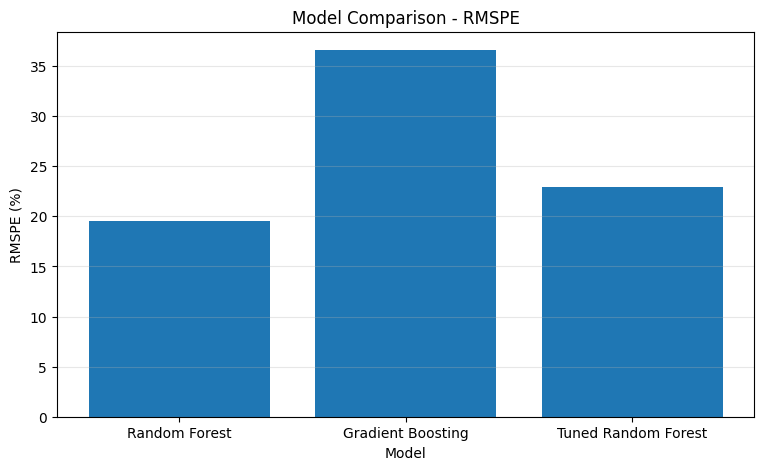

In [57]:
import matplotlib.pyplot as plt

# Model comparison
models = ["Random Forest", "Gradient Boosting", "Tuned Random Forest"]
rmspe_values = [19.56, 36.59, 22.97]

plt.figure(figsize=(9, 5))
plt.bar(models, rmspe_values)

plt.title("Model Comparison - RMSPE")
plt.xlabel("Model")
plt.ylabel("RMSPE (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

## Feature Importance Analysis

The Random Forest model was used to identify the variables that contributed most to sales predictions.

The most important features were:

- **Competition Distance** – stores' proximity to competitors had a strong relationship with sales.
- **Promotion** – promotional activity was one of the strongest predictors of sales.
- **Store** – individual store characteristics significantly influenced sales.
- **Competition Opening Year and Month** – the timing of competitor entry was also important.
- **Day of Week** – sales varied considerably across different days.
- **Competition Open Months** – the duration for which competition had been present affected predictions.

Overall, the feature importance analysis suggests that **promotional activity, store characteristics, competition and time-related factors** are important determinants of Rossmann store sales.

# 15. Final Results

The machine learning models were evaluated using MAE, RMSE and RMSPE on a chronological validation dataset.

| Model | MAE | RMSE | RMSPE |
|---|---:|---:|---:|
| Random Forest | 906.78 | 1337.28 | 19.56% |
| Gradient Boosting | 1520.98 | 2072.88 | 36.59% |
| Tuned Random Forest | 1011.55 | 1397.74 | 22.97% |

The Random Forest model achieved the lowest validation RMSPE among the models tested, with an RMSPE of approximately **19.56%**.

The final forecasting model generated sales predictions for **41,088 test observations**, which were exported into a CSV file.

# 16. Conclusion

This project developed a machine learning pipeline for forecasting Rossmann store sales.

The analysis showed that **promotional activity, store characteristics, competition and time-related variables** are important factors associated with sales.

Three machine learning approaches were evaluated: Random Forest, Gradient Boosting and a Tuned Random Forest. Based on the validation results, the Random Forest model produced the lowest RMSPE of **19.56%**.

The final model was then used to forecast sales for the **41,088 observations in the test dataset**. These predictions were exported as a CSV file.

Overall, the project demonstrates how historical retail data and machine learning can be used to generate sales forecasts and identify factors associated with store performance.